# 08 — GRPO from scratch

## Learning objectives

- Generate same-prompt groups and compute normalized outcome advantages.
- Handle constant-reward groups without NaN.
- Train a contextual one-token policy with PPO-style ratio updates and reference KL.

This notebook runs a small CPU demonstration by default. Synthetic experiments are educational, not evidence of LLM alignment. Pretrained-model downloads and GPU training require explicit opt-in. All runtime outputs stay inside `RLHF_NOTEBOOKS/`.

**Source connection:** GRPO PDF [1,0,1,0] and [9,6,2] examples; Final_GRPO_Practical.ipynb heuristic versus GSM8K paths; notes Chapter06; DeepSeekMath arXiv2402.03300.

[Learning order and setup](README.md).

In [1]:
from pathlib import Path
import os, sys, json, math, random, copy, re, subprocess, hashlib
# Find this collection when launched from the repository, module, or notebook directory.
candidates = [Path.cwd(), Path.cwd()/'RLHF_NOTEBOOKS', Path.cwd()/'13_rlhf_ppo_dpo_orpo/RLHF_NOTEBOOKS']
ROOT = next((p.resolve() for p in candidates if (p/'source_inspection.json').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter from RLHF_NOTEBOOKS, its parent, or the repository root.')
RUNTIME = ROOT/'runtime'; RUNTIME.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(RUNTIME/'matplotlib')
os.environ['HF_HOME'] = str(RUNTIME/'huggingface')
os.environ['HF_DATASETS_CACHE'] = str(RUNTIME/'huggingface/datasets')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42); torch.manual_seed(42)
torch.set_num_threads(1)
print('Python', sys.version.split()[0], 'PyTorch', torch.__version__, 'CUDA', torch.cuda.is_available())

Python 3.13.9 PyTorch 2.8.0+cpu CUDA False


## Group-relative outcome objective

$$
\mu_x=\frac1G\sum_iR_i,\quad s_x=\sqrt{\frac1G\sum_i(R_i-\mu_x)^2},\quad \hat A_i=\frac{R_i-\mu_x}{s_x+\varepsilon_{norm}}.
$$
$G$ same-prompt responses, $R_i$ outcome reward, $\mu_x$ group mean, $s_x$ population std in this demo and $\varepsilon_{norm}$ stabilizer. Rewards $[1,0,1,0]$ give advantages $[1,-1,1,-1]$. Equal rewards give zero advantages, not successful learning.

$$
J=\mathbb E\frac1G\sum_i\frac1{T_i}\sum_t\left[\min(\rho_{i,t}\hat A_i,\operatorname{clip}(\rho_{i,t},1-\epsilon,1+\epsilon)\hat A_i)-\kappa\hat K_{i,t}\right].
$$
$T_i$ response length, $\rho$ current/old token ratio, $\epsilon$ clipping and $\kappa$ reference KL weight. Original GRPO averages each response, then groups. Later DAPO/token-mean variants change weighting; your source notebook's recorded default was DAPO. No critic is learned in original GRPO, but baseline/advantage calculations remain. Original paper also allows process rewards and learned reward models.

The code simplifies responses to one categorical token ($T=1$). Exact full-distribution KL is used instead of sampled $q-\log q-1$, where $q=\pi_{ref}/\pi_\theta$, avoiding reused-old-sample expectation ambiguity in this finite action space.

Source group [9,6,2]: [[1.1624765396118164, 0.11624769866466522, -1.2787240743637085]]


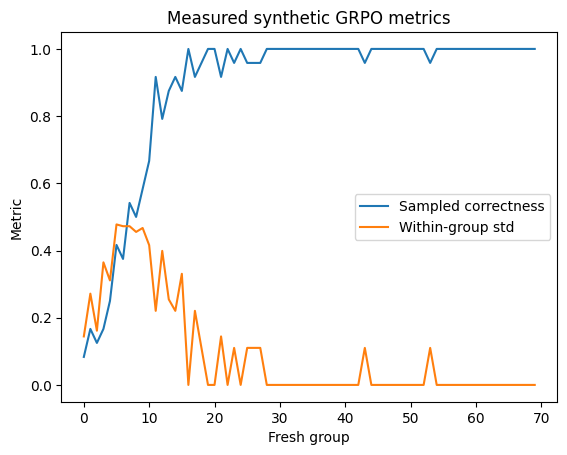

Correct-answer probabilities: [0.9969075322151184, 0.9955480098724365, 0.9963886737823486]


In [2]:
def group_advantages(rewards,epsilon=1e-8):
    if rewards.ndim!=2 or rewards.shape[1]<2:raise ValueError('Need [prompts, group>=2] rewards')
    centered=rewards-rewards.mean(-1,keepdim=True)
    return centered/(rewards.std(-1,keepdim=True,unbiased=False)+epsilon)
assert torch.allclose(group_advantages(torch.tensor([[1.,0.,1.,0.]])),torch.tensor([[1.,-1.,1.,-1.]]))
assert torch.equal(group_advantages(torch.ones(2,4)),torch.zeros(2,4))
print('Source group [9,6,2]:',group_advantages(torch.tensor([[9.,6.,2.]])).tolist())
# Synthetic one-token arithmetic policy: actions represent candidate integers 0..9.
# This is a contextual bandit special case of outcome-GRPO (response length T=1).
policy_logits=nn.Parameter(torch.zeros(3,10));ref_logps=torch.full((3,10),-math.log(10))
optimizer=torch.optim.Adam([policy_logits],lr=.12);gold=torch.tensor([2,4,6]);history=[];variance=[]
for iteration in range(70):
    with torch.no_grad():
        old=torch.distributions.Categorical(logits=policy_logits.detach())
        actions=old.sample((8,)).T  # [3 prompts, 8 completions each]
        old_selected=F.log_softmax(policy_logits.detach(),-1).gather(1,actions)
        rewards=actions.eq(gold[:,None]).float();adv=group_advantages(rewards)
    for epoch in range(2):
        logps=F.log_softmax(policy_logits,-1);selected=logps.gather(1,actions)
        ratio=(selected-old_selected).exp()
        surrogate=torch.minimum(ratio*adv,ratio.clamp(.8,1.2)*adv).mean()
        # Exact full action KL removes reused-sample estimator ambiguity in this T=1 demo.
        kl=(logps.exp()*(logps-ref_logps)).sum(-1).mean()
        loss=-surrogate+.01*kl
        optimizer.zero_grad();loss.backward();assert torch.isfinite(policy_logits.grad).all();optimizer.step()
    history.append(rewards.mean().item());variance.append(rewards.std(-1,unbiased=False).mean().item())
plt.plot(history,label='Sampled correctness');plt.plot(variance,label='Within-group std');plt.xlabel('Fresh group');plt.ylabel('Metric');plt.title('Measured synthetic GRPO metrics');plt.legend();plt.show()
print('Correct-answer probabilities:',F.softmax(policy_logits,-1)[torch.arange(3),gold].detach().tolist())

## Exercises

1. Force identical rewards and confirm only KL can update.
2. Compare population and sample std.
3. Add variable-length toy responses and contrast per-response versus batch-token weighting.

## Key takeaways

Recompute the worked examples, inspect masks and gradients, and evaluate independently of the training objective. A small training-loss decrease does not establish generalization or alignment. Record the model, data split, seeds and dependency versions before interpreting results.